In [9]:
!pip install gdown

In [ ]:
import gdown 

file_id = '1mltAgDVdiLWQiyVNldg0v5Up7-vk_9zs'
url = f'https://drive.google.com/uc?id=1mltAgDVdiLWQiyVNldg0v5Up7-vk_9zs'
#https://drive.google.com/file/d/1mltAgDVdiLWQiyVNldg0v5Up7-vk_9zs/view?usp=sharing
gdown.download(url, 'turmeric_dataset.zip', quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=1mltAgDVdiLWQiyVNldg0v5Up7-vk_9zs
From (redirected): https://drive.google.com/uc?id=1mltAgDVdiLWQiyVNldg0v5Up7-vk_9zs&confirm=t&uuid=020e449b-442f-4ddb-9376-6572e821a52c
To: /kaggle/working/turmeric_dataset.zip
100%|██████████| 3.30G/3.30G [01:06<00:00, 49.5MB/s]


'turmeric_dataset.zip'

In [13]:
!unzip -q turmeric_dataset.zip -d dataset/

In [14]:
ls -l /kaggle/working/turmeric_dataset.zip

-rw-r--r-- 1 root root 3298394526 Jul 26 14:34 /kaggle/working/turmeric_dataset.zip


In [ ]:
import os

dataset_path = 'dataset/Image Dataset for Turmeric Plant Leaf Disease Detection/'

for main_folder in os.listdir(dataset_path):
    main_folder_path = os.path.join(dataset_path, main_folder)
    
    if os.path.isdir(main_folder_path):
        print(f"\n📂 {main_folder}")
        
        for disease_folder in os.listdir(main_folder_path):
            disease_path = os.path.join(main_folder_path, disease_folder)
            
            if os.path.isdir(disease_path):
                
                num_images = len(os.listdir(disease_path))
                print(f"   ↳ 📁 {disease_folder} ({num_images} images)")


📂 Original DataSet
   ↳ 📁 Leaf_Spot (193 images)
   ↳ 📁 Aphids_Disease (221 images)
   ↳ 📁 Blotch (238 images)
   ↳ 📁 Healthy_Leaf (213 images)

📂 Augmented DataSet
   ↳ 📁 Leaf_Spot (919 images)
   ↳ 📁 Aphids_Disease (847 images)
   ↳ 📁 Blotch (909 images)
   ↳ 📁 Healthy_Leaf (821 images)


## 1. Setup cpu or gpu

In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F


from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

import matplotlib.pyplot as plt
import numpy as np
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

torch.manual_seed(0)
np.random.seed(0)

Using device: cuda


## 2. Get the data



In [ ]:
data_dir = 'dataset/Image Dataset for Turmeric Plant Leaf Disease Detection/Augmented DataSet'

print("Dataset folder:", data_dir)
print("Classes available:", os.listdir(data_dir))

Dataset folder: dataset/Image Dataset for Turmeric Plant Leaf Disease Detection/Augmented DataSet
Classes available: ['Leaf_Spot', 'Aphids_Disease', 'Blotch', 'Healthy_Leaf']


## 3. Load the images  basic transform 

In [ ]:
IMG_SIZE = 128
BATCH_SIZE = 32

basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

full_dataset = datasets.ImageFolder(data_dir, transform=basic_transform)

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_ds, val_ds = random_split(full_dataset, [train_size, val_size])

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)

print("Classes:", full_dataset.classes)          
print("Train images:", len(train_ds))
print("Val images  :", len(val_ds))

Classes: ['Aphids_Disease', 'Blotch', 'Healthy_Leaf', 'Leaf_Spot']
Train images: 2796
Val images  : 700


### Look at a few images

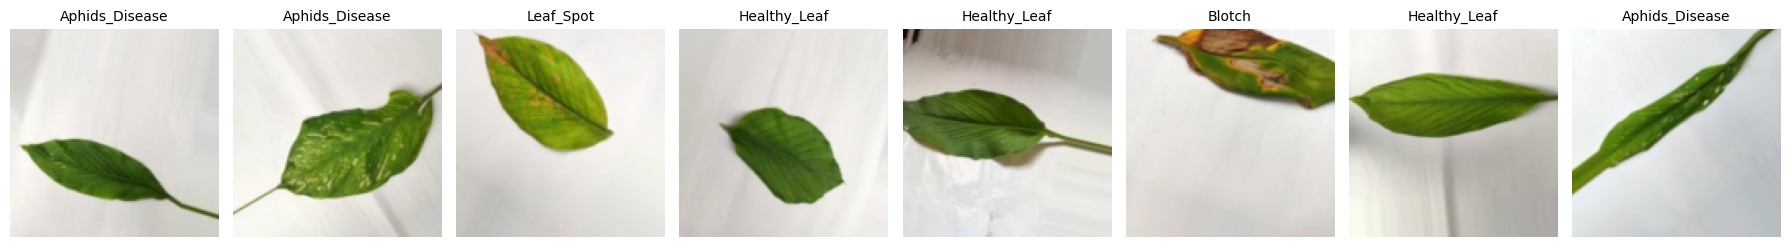

In [ ]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(1, 8, figsize=(18, 4))
for i, ax in enumerate(axes):
    
    img = images[i].numpy().transpose((1, 2, 0))
    ax.imshow(img)
    
    class_name = full_dataset.classes[labels[i]]
    ax.set_title(class_name, fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

## 4. Build CNN

In [ ]:
class TurmericCNN(nn.Module):
    def __init__(self):
        super(TurmericCNN, self).__init__()
        
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        
        self.fc1 = nn.Linear(64 * 16 * 16, 512)
        
        self.fc2 = nn.Linear(512, 4)

    def forward(self, x):
        
        x = self.pool(F.relu(self.conv1(x)))
        
        x = self.pool(F.relu(self.conv2(x)))
        
        x = self.pool(F.relu(self.conv3(x)))
        
        x = torch.flatten(x, 1)
        
        x = F.relu(self.fc1(x))
        x = self.fc2(x) 
        return x

model = TurmericCNN().to(device)
print(model)

TurmericCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=16384, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=4, bias=True)
)


## 5. Define the Loss Function and Optimizer

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
print("done")

done


## 6. The Training Loop 

In [ ]:
EPOCHS = 30

train_losses, val_losses = [], []
train_accs, val_accs = [], []

print("Starting Training...")

for epoch in range(EPOCHS):
   
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()        # 1. Clear old gradients
        outputs = model(images)      # 2. Forward pass (make predictions)
        loss = criterion(outputs, labels) # 3. Calculate loss
        loss.backward()              # 4. Backward pass (calculate gradients)
        optimizer.step()             # 5. Update weights
        
        running_loss += loss.item()
        
        # Calculate accuracy
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
    epoch_train_loss = running_loss / len(train_loader)
    epoch_train_acc = 100 * correct_train / total_train
    
    # VALIDATION PHASE 
    model.eval() # Set model to evaluation mode (turns off things like dropout)
    running_val_loss = 0.0
    correct_val = 0
    total_val = 0
    
    # We don't need to calculate gradients for validation
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            running_val_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()
            
    epoch_val_loss = running_val_loss / len(val_loader)
    epoch_val_acc = 100 * correct_val / total_val
    
    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accs.append(epoch_train_acc)
    val_accs.append(epoch_val_acc)
    
    print(f"Epoch [{epoch+1}/{EPOCHS}] | "
          f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.2f}% | "
          f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.2f}%")

print("Training Complete!")

Starting Training...
Epoch [1/30] | Train Loss: 1.3619, Train Acc: 29.58% | Val Loss: 1.1533, Val Acc: 40.00%
Epoch [2/30] | Train Loss: 1.0148, Train Acc: 52.04% | Val Loss: 0.9008, Val Acc: 60.14%
Epoch [3/30] | Train Loss: 0.8177, Train Acc: 63.63% | Val Loss: 0.7723, Val Acc: 65.29%
Epoch [4/30] | Train Loss: 0.7357, Train Acc: 67.78% | Val Loss: 0.7941, Val Acc: 64.71%
Epoch [5/30] | Train Loss: 0.6762, Train Acc: 70.82% | Val Loss: 0.6858, Val Acc: 66.29%
Epoch [6/30] | Train Loss: 0.6129, Train Acc: 74.61% | Val Loss: 0.6189, Val Acc: 74.29%
Epoch [7/30] | Train Loss: 0.5246, Train Acc: 77.61% | Val Loss: 0.6703, Val Acc: 69.57%
Epoch [8/30] | Train Loss: 0.4817, Train Acc: 80.11% | Val Loss: 0.5611, Val Acc: 75.43%
Epoch [9/30] | Train Loss: 0.4002, Train Acc: 82.80% | Val Loss: 0.4991, Val Acc: 79.43%
Epoch [10/30] | Train Loss: 0.3093, Train Acc: 87.34% | Val Loss: 0.4756, Val Acc: 79.57%
Epoch [11/30] | Train Loss: 0.2611, Train Acc: 90.09% | Val Loss: 0.4479, Val Acc: 82.14

## 7. Plotting the Results 

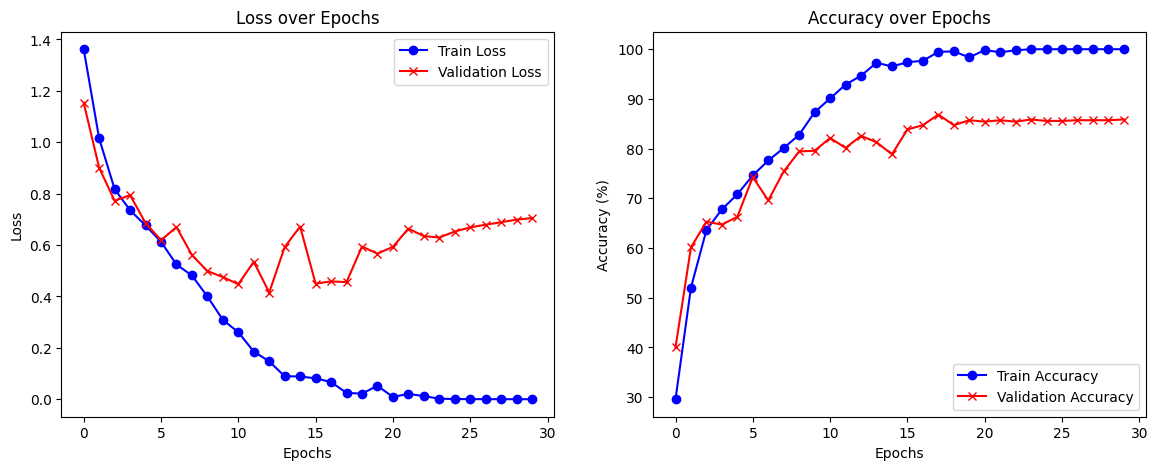

In [23]:
# Plot Loss and Accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss Curve
ax1.plot(train_losses, label='Train Loss', color='blue', marker='o')
ax1.plot(val_losses, label='Validation Loss', color='red', marker='x')
ax1.set_title('Loss over Epochs')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()

# Accuracy Curve
ax2.plot(train_accs, label='Train Accuracy', color='blue', marker='o')
ax2.plot(val_accs, label='Validation Accuracy', color='red', marker='x')
ax2.set_title('Accuracy over Epochs')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()

plt.show()

## 8. Data Augmentation & Dropout

In [ ]:
aug_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5), 
    transforms.RandomRotation(15),          
    transforms.ToTensor(),
])

augmented_dataset = datasets.ImageFolder(data_dir, transform=aug_transform)

train_ds_aug, val_ds_aug = random_split(augmented_dataset, [train_size, val_size])

train_loader_aug = DataLoader(train_ds_aug, batch_size=BATCH_SIZE, shuffle=True)
val_loader_aug   = DataLoader(val_ds_aug,   batch_size=BATCH_SIZE, shuffle=False)

print("Round 2 DataLoaders Ready!")

Round 2 DataLoaders Ready!


### Creating the Dropout Model

In [ ]:
class TurmericCNN_Dropout(nn.Module):
    def __init__(self):
        super(TurmericCNN_Dropout, self).__init__()
        
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        
        self.dropout = nn.Dropout(0.5)
        
        self.fc1 = nn.Linear(64 * 16 * 16, 512)
        self.fc2 = nn.Linear(512, 4)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        
        x = torch.flatten(x, 1)
        
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

model_round2 = TurmericCNN_Dropout().to(device)
criterion = nn.CrossEntropyLoss()
optimizer_round2 = torch.optim.Adam(model_round2.parameters(), lr=0.001)

print(model_round2)

TurmericCNN_Dropout(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=16384, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=4, bias=True)
)


## 9. Train 

In [ ]:
EPOCHS = 30
train_losses_2, val_losses_2 = [], []
train_accs_2, val_accs_2 = [], []

print("Starting Round 2 Training...")

for epoch in range(EPOCHS):
    
    model_round2.train() 
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for images, labels in train_loader_aug:
        images, labels = images.to(device), labels.to(device)
        
        optimizer_round2.zero_grad()        
        outputs = model_round2(images)      
        loss = criterion(outputs, labels) 
        loss.backward()              
        optimizer_round2.step()             
        
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
    epoch_train_loss = running_loss / len(train_loader_aug)
    epoch_train_acc = 100 * correct_train / total_train
    
    
    model_round2.eval() 
    running_val_loss = 0.0
    correct_val = 0
    total_val = 0
    
    with torch.no_grad():
        for images, labels in val_loader_aug:
            images, labels = images.to(device), labels.to(device)
            outputs = model_round2(images)
            loss = criterion(outputs, labels)
            
            running_val_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()
            
    epoch_val_loss = running_val_loss / len(val_loader_aug)
    epoch_val_acc = 100 * correct_val / total_val
    
    train_losses_2.append(epoch_train_loss)
    val_losses_2.append(epoch_val_loss)
    train_accs_2.append(epoch_train_acc)
    val_accs_2.append(epoch_val_acc)
    
    print(f"Epoch [{epoch+1}/{EPOCHS}] | Train Acc: {epoch_train_acc:.2f}% | Val Acc: {epoch_val_acc:.2f}%")

print("Round 2 Complete! You now have a robust Disease Detection model.")

Starting Round 2 Training...
Epoch [1/30] | Train Acc: 37.70% | Val Acc: 51.43%
Epoch [2/30] | Train Acc: 56.62% | Val Acc: 68.29%
Epoch [3/30] | Train Acc: 65.06% | Val Acc: 72.57%
Epoch [4/30] | Train Acc: 70.71% | Val Acc: 64.71%
Epoch [5/30] | Train Acc: 73.50% | Val Acc: 76.57%
Epoch [6/30] | Train Acc: 73.89% | Val Acc: 70.14%
Epoch [7/30] | Train Acc: 74.93% | Val Acc: 79.71%
Epoch [8/30] | Train Acc: 78.22% | Val Acc: 78.14%
Epoch [9/30] | Train Acc: 78.11% | Val Acc: 79.57%
Epoch [10/30] | Train Acc: 80.51% | Val Acc: 82.29%
Epoch [11/30] | Train Acc: 81.40% | Val Acc: 81.29%
Epoch [12/30] | Train Acc: 81.12% | Val Acc: 79.86%
Epoch [13/30] | Train Acc: 82.62% | Val Acc: 83.71%
Epoch [14/30] | Train Acc: 84.76% | Val Acc: 86.57%
Epoch [15/30] | Train Acc: 84.80% | Val Acc: 86.14%
Epoch [16/30] | Train Acc: 84.91% | Val Acc: 85.14%
Epoch [17/30] | Train Acc: 88.05% | Val Acc: 90.71%
Epoch [18/30] | Train Acc: 89.27% | Val Acc: 90.14%
Epoch [19/30] | Train Acc: 87.91% | Val Acc:

## 10. Plotting the Results 

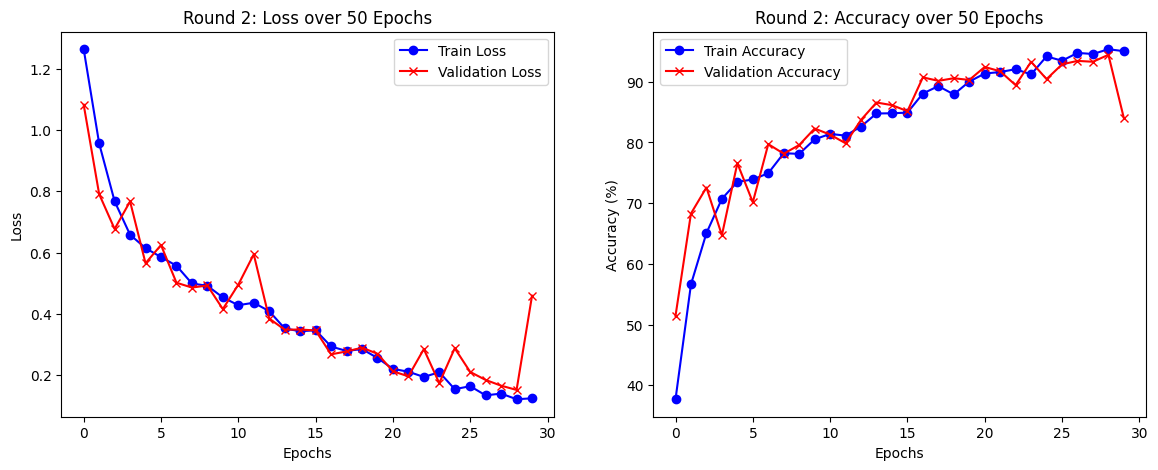

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))


ax1.plot(train_losses_2, label='Train Loss', color='blue', marker='o')
ax1.plot(val_losses_2, label='Validation Loss', color='red', marker='x')
ax1.set_title('Round 2: Loss over 50 Epochs')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()

ax2.plot(train_accs_2, label='Train Accuracy', color='blue', marker='o')
ax2.plot(val_accs_2, label='Validation Accuracy', color='red', marker='x')
ax2.set_title('Round 2: Accuracy over 50 Epochs')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()

plt.show()

## 11. Visualizing the CNN Filters

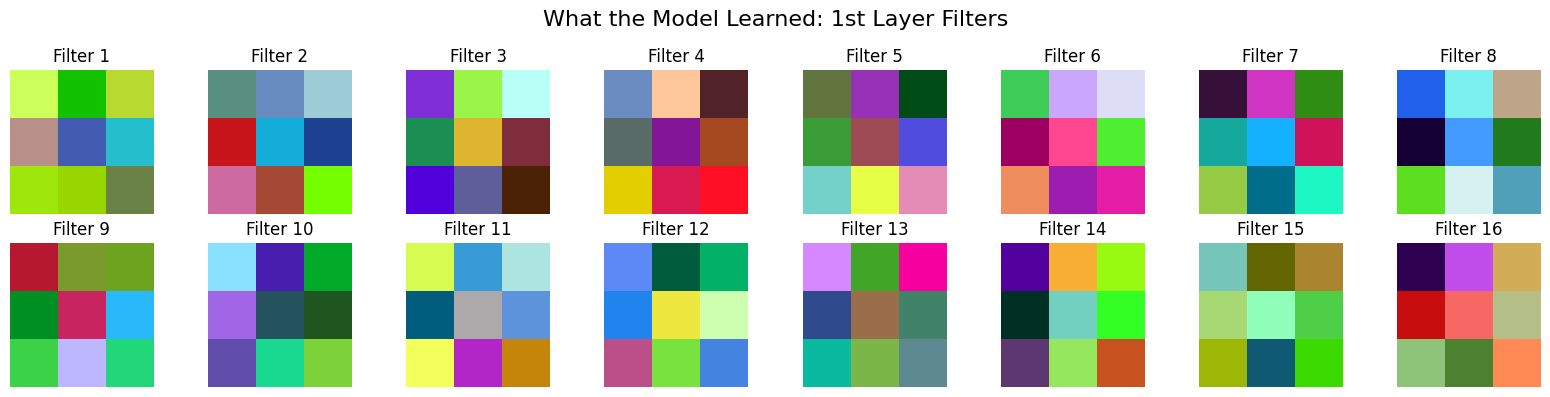

In [ ]:
filters = model_round2.conv1.weight.data.cpu().numpy()

fig, axes = plt.subplots(2, 8, figsize=(16, 4))

for i, ax in enumerate(axes.flat):
  
    f = filters[i]
    
    f_min, f_max = f.min(), f.max()
    f = (f - f_min) / (f_max - f_min)
    
    ax.imshow(f.transpose(1, 2, 0))
    ax.set_title(f'Filter {i+1}')
    ax.axis('off')

plt.suptitle('What the Model Learned: 1st Layer Filters', fontsize=16)
plt.tight_layout()
plt.show()

## 12. Testing the Model on a Random Image

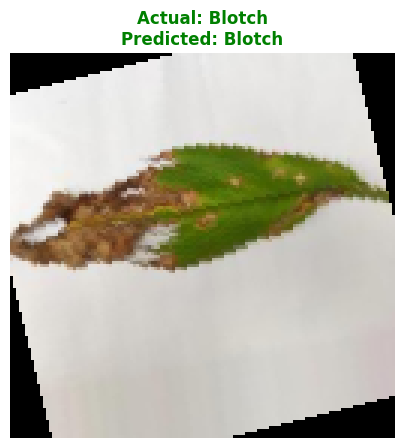

In [ ]:
import random

random_idx = random.randint(0, len(val_ds_aug) - 1)
image, label = val_ds_aug[random_idx]

image_tensor = image.unsqueeze(0).to(device)

model_round2.eval() 
with torch.no_grad():
    output = model_round2(image_tensor)
    _, predicted_idx = torch.max(output, 1)

class_names = augmented_dataset.classes
actual_disease = class_names[label]
predicted_disease = class_names[predicted_idx.item()]

img_display = image.numpy().transpose((1, 2, 0))

plt.figure(figsize=(5, 5))
plt.imshow(img_display)

title_color = "green" if actual_disease == predicted_disease else "red"
plt.title(f"Actual: {actual_disease}\nPredicted: {predicted_disease}", 
          color=title_color, fontweight='bold', fontsize=12)
plt.axis('off')
plt.show()

## 13. Confusion Matrix 

================ CLASSIFICATION REPORT ================
                precision    recall  f1-score   support

Aphids_Disease       0.94      0.87      0.90       162
        Blotch       1.00      0.57      0.73       187
  Healthy_Leaf       0.85      0.99      0.92       159
     Leaf_Spot       0.71      0.95      0.81       192

      accuracy                           0.84       700
     macro avg       0.88      0.85      0.84       700
  weighted avg       0.87      0.84      0.84       700



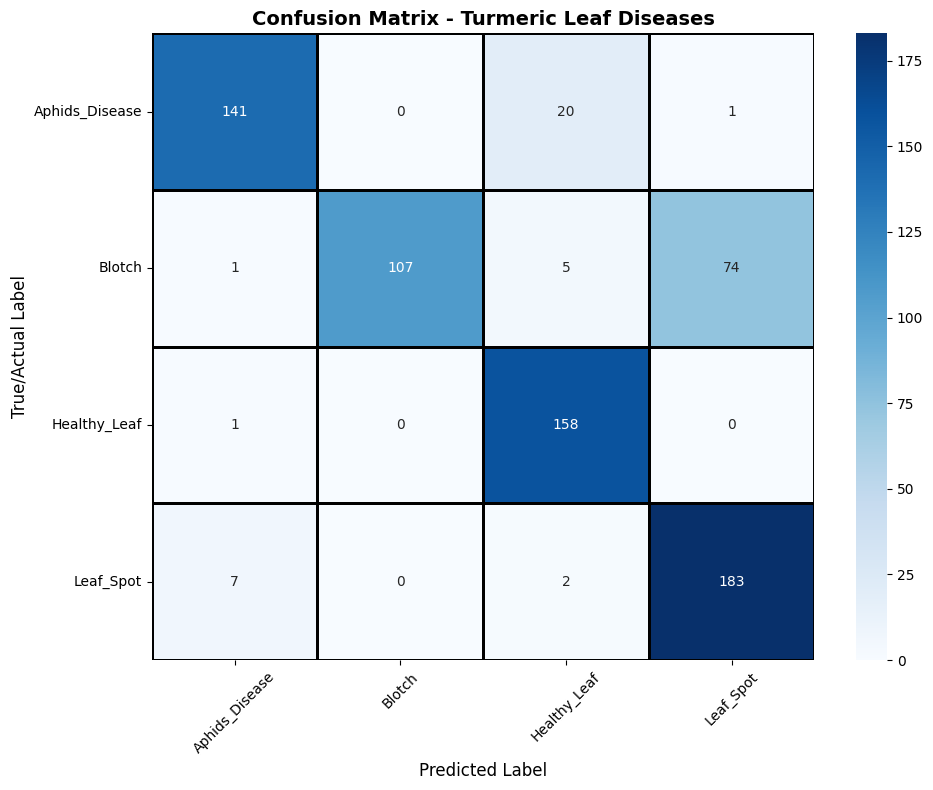

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import pandas as pd

model_round2.eval() 
all_preds = []
all_true = []

with torch.no_grad():
    for images, labels in val_loader_aug:
        images, labels = images.to(device), labels.to(device)
        outputs = model_round2(images)
        _, predicted = torch.max(outputs.data, 1)
        
        all_preds.extend(predicted.cpu().numpy())
        all_true.extend(labels.cpu().numpy())

class_names = augmented_dataset.classes

print(classification_report(all_true, all_preds, target_names=class_names))

cm = confusion_matrix(all_true, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names,
            linewidths=1, linecolor='black')

plt.title('Confusion Matrix - Turmeric Leaf Diseases', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True/Actual Label', fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()